<a href="https://colab.research.google.com/github/gouthamsankar-clg/BIS_Lab/blob/main/Lab_6/PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Optimization Complete! Final Best Cost: 41.18
Optimal Collision-Free Waypoints (Row, Col):
  Waypoint 0: (1.00, 1.00)
  Waypoint 1: (4.49, 9.41)
  Waypoint 2: (7.92, 10.37)
  Waypoint 3: (11.15, 11.13)
  Waypoint 4: (13.89, 11.67)
  Waypoint 5: (16.48, 12.35)
  Waypoint 6: (18.88, 13.87)
  Waypoint 7: (23.00, 23.00)


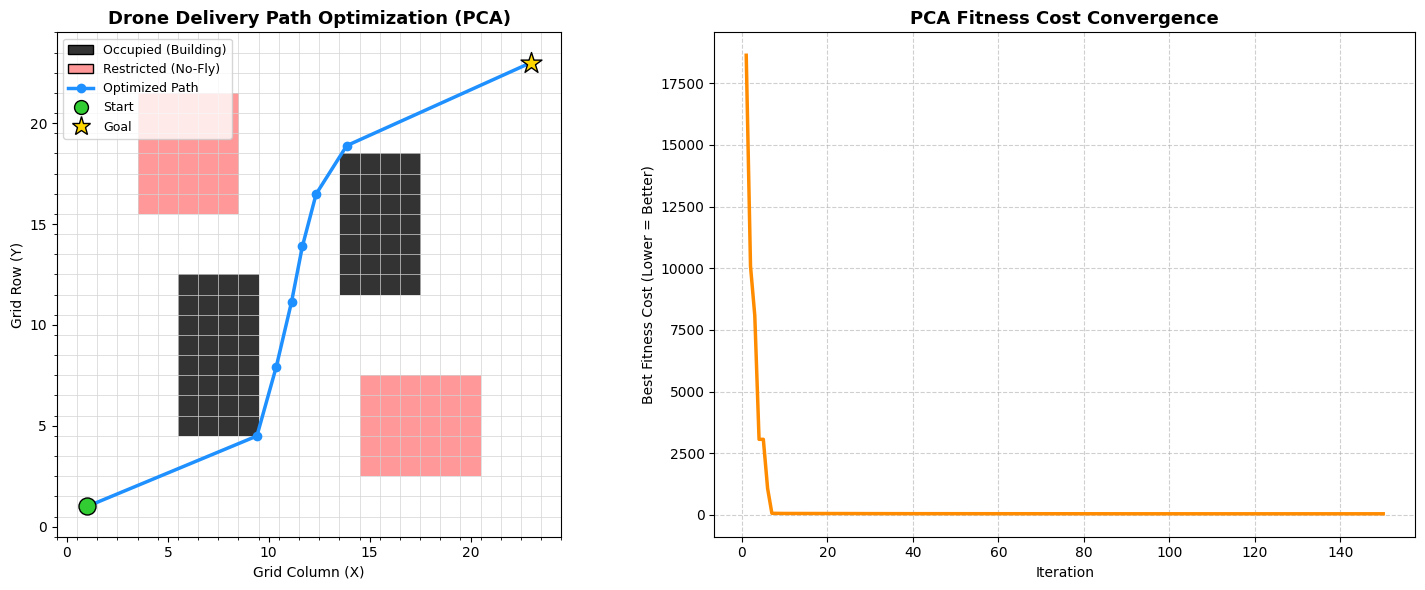

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from concurrent.futures import ThreadPoolExecutor

# ==========================================
# 1. SETUP ENVIRONMENT & PARAMETERS (No Input Needed)
# ==========================================
M, N = 25, 25  # Physical map dimensions
EnvGrid = np.zeros((M, N), dtype=int)

# Define Obstacles: 1 = Occupied (Building), 2 = Restricted (No-Fly Zone)
EnvGrid[5:13, 6:10] = 1     # Building 1
EnvGrid[12:19, 14:18] = 1   # Building 2
EnvGrid[3:8, 15:21] = 2     # Restricted Airspace 1
EnvGrid[16:22, 4:9] = 2     # Restricted Airspace 2

Start = np.array([1.0, 1.0])
Goal = np.array([23.0, 23.0])

# PCA Parameters
PopRows, PopCols = 8, 8     # 64 candidate paths evolving simultaneously
NumWaypoints = 6            # Intermediate turning points per path
MaxIters = 150
Alpha = 0.5                 # Learning rate
w1, w2, w3 = 1.0, 0.4, 1.0  # Fitness weights (Distance, Energy, Penalty)

np.random.seed(42)  # For reproducible visual output

# ==========================================
# 2. OBJECTIVE (FITNESS) FUNCTION
# ==========================================
def Fitness(Path, EnvGrid, Start, Goal):
    FullPath = np.vstack([Start, Path, Goal])
    Dist = 0.0
    Energy = 0.0
    Penalty = 0.0

    for i in range(len(FullPath) - 1):
        p1, p2 = FullPath[i], FullPath[i + 1]
        seg_len = np.linalg.norm(p2 - p1)
        Dist += seg_len

        # Energy penalty based on sharp directional changes
        if i > 0:
            v1 = FullPath[i] - FullPath[i - 1]
            v2 = p2 - p1
            Energy += np.linalg.norm(v2 - v1)

        # Check intermediate points along segment for collisions
        steps = max(int(seg_len * 3), 1)
        for s in range(steps + 1):
            pt = np.round(p1 + (p2 - p1) * (s / steps)).astype(int)
            pt = np.clip(pt, 0, M - 1)
            cell_val = EnvGrid[pt[0], pt[1]]
            if cell_val == 1:
                Penalty += 1000.0  # Building collision penalty
            elif cell_val == 2:
                Penalty += 500.0   # Restricted zone penalty

    return (w1 * Dist) + (w2 * Energy) + (w3 * Penalty)

def GetMooreNeighbors(r, c, rows, cols):
    neighbors = []
    for dr in [-1, 0, 1]:
        for dc in [-1, 0, 1]:
            if dr == 0 and dc == 0:
                continue
            neighbors.append(((r + dr) % rows, (c + dc) % cols))
    return neighbors

# ==========================================
# 3. PARALLEL CELLULAR ALGORITHM EXECUTION
# ==========================================
def PCA_Drone_Path_Optimization():
    GlobalBestCost = float('inf')
    GlobalBestPath = None
    cost_history = []

    # Initialize random candidate paths across the cellular grid
    PopGrid = np.random.uniform(0, M - 1, size=(PopRows, PopCols, NumWaypoints, 2))

    with ThreadPoolExecutor() as executor:
        for iteration in range(MaxIters):
            # Evaluate Fitness in Parallel
            flat_paths = [PopGrid[r, c] for r in range(PopRows) for c in range(PopCols)]
            flat_costs = list(executor.map(lambda p: Fitness(p, EnvGrid, Start, Goal), flat_paths))
            Cost = np.array(flat_costs).reshape(PopRows, PopCols)

            # Track Global Best Solution
            min_idx = np.unravel_index(np.argmin(Cost), Cost.shape)
            if Cost[min_idx] < GlobalBestCost:
                GlobalBestCost = Cost[min_idx]
                GlobalBestPath = PopGrid[min_idx].copy()

            cost_history.append(GlobalBestCost)

            # Synchronous Parallel State Update
            NewGrid = np.zeros_like(PopGrid)
            decay = 1.0 - (iteration / MaxIters)

            for r in range(PopRows):
                for c in range(PopCols):
                    Neighbors = GetMooreNeighbors(r, c, PopRows, PopCols)
                    BestN = min(Neighbors, key=lambda n: Cost[n[0], n[1]])
                    Noise = np.random.normal(0, 0.35 * decay, size=(NumWaypoints, 2))

                    # PCA State Update Rule
                    updated_path = PopGrid[r, c] + Alpha * (PopGrid[BestN] - PopGrid[r, c]) + Noise
                    NewGrid[r, c] = np.clip(updated_path, 0, M - 1)

            PopGrid = NewGrid

    return np.vstack([Start, GlobalBestPath, Goal]), GlobalBestCost, cost_history

# Run Optimization
BestRoute, FinalCost, History = PCA_Drone_Path_Optimization()

print(f"Optimization Complete! Final Best Cost: {FinalCost:.2f}")
print("Optimal Collision-Free Waypoints (Row, Col):")
for idx, pt in enumerate(BestRoute):
    print(f"  Waypoint {idx}: ({pt[0]:.2f}, {pt[1]:.2f})")

# ==========================================
# 4. VISUALIZATION
# ==========================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Environment Map & Optimized Drone Path
cmap_colors = np.ones((M, N, 3))          # Free space = White
cmap_colors[EnvGrid == 1] = [0.2, 0.2, 0.2]  # Buildings = Dark Gray
cmap_colors[EnvGrid == 2] = [1.0, 0.6, 0.6]  # Restricted = Light Red

ax1.imshow(cmap_colors, origin='lower')
ax1.set_xticks(np.arange(-0.5, N, 1), minor=True)
ax1.set_yticks(np.arange(-0.5, M, 1), minor=True)
ax1.grid(which='minor', color='lightgray', linestyle='-', linewidth=0.5)

# Plot Drone Path (Note: x-axis = Col, y-axis = Row)
ax1.plot(BestRoute[:, 1], BestRoute[:, 0], color='dodgerblue', linewidth=2.5, marker='o', markersize=6, label='Optimal Drone Path')
ax1.scatter(Start[1], Start[0], color='limegreen', s=150, edgecolors='black', zorder=5, label='Start (Depot)')
ax1.scatter(Goal[1], Goal[0], color='gold', marker='*', s=250, edgecolors='black', zorder=5, label='Goal (Drop-off)')

# Legend patches for obstacles
legend_elements = [
    patches.Patch(facecolor=[0.2, 0.2, 0.2], edgecolor='black', label='Occupied (Building)'),
    patches.Patch(facecolor=[1.0, 0.6, 0.6], edgecolor='black', label='Restricted (No-Fly)'),
    plt.Line2D([0], [0], color='dodgerblue', lw=2.5, marker='o', label='Optimized Path'),
    plt.Line2D([0], [0], color='w', marker='o', markerfacecolor='limegreen', markeredgecolor='k', markersize=10, label='Start'),
    plt.Line2D([0], [0], color='w', marker='*', markerfacecolor='gold', markeredgecolor='k', markersize=14, label='Goal')
]
ax1.legend(handles=legend_elements, loc='upper left', fontsize=9)
ax1.set_title("Drone Delivery Path Optimization (PCA)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Grid Column (X)")
ax1.set_ylabel("Grid Row (Y)")

# Plot 2: Fitness Convergence Over Iterations
ax2.plot(range(1, MaxIters + 1), History, color='darkorange', linewidth=2.5)
ax2.set_title("PCA Fitness Cost Convergence", fontsize=13, fontweight='bold')
ax2.set_xlabel("Iteration")
ax2.set_ylabel("Best Fitness Cost (Lower = Better)")
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()